# Etapa 1 · Preprocesamiento y *data leakage*
**Proyecto Integrador — predicción de falla cardíaca (Heart Failure Prediction, Kaggle)**

Qué vamos a hacer, en orden:
1. Cargar los datos y mirarlos.
2. Entender qué es el *data leakage* viéndolo con números.
3. Construir `Pipeline`s dentro de `GridSearchCV` (la forma correcta).
4. Comparar varios modelos y hacer un ranking.

Ejecuta las celdas **una por una** y lee la explicación antes de correr cada una.

## 0. Preparación
Sube el archivo `heart.csv` que descargaste de Kaggle cuando Colab te lo pida
(botón *Choose files*). Si lo corres fuera de Colab, deja `heart.csv` junto al notebook.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42

try:  # en Colab
    from google.colab import files
    subido = files.upload()
    RUTA = next(iter(subido))
except ImportError:  # fuera de Colab
    RUTA = "heart.csv"
print("Archivo:", RUTA)

Saving heart.csv to heart.csv
Archivo: heart.csv


## 1. Cargar y mirar los datos
La variable respuesta es `HeartDisease` (1 = enfermedad, 0 = normal). El código también
acepta la versión UCI, donde se llama `target`.

In [2]:
df = pd.read_csv(RUTA, encoding="utf-8-sig")
TARGET = "HeartDisease" if "HeartDisease" in df.columns else "target"

print("Filas, columnas:", df.shape)
print("Valores nulos en total:", int(df.isna().sum().sum()))
print("\nTipos de dato:")
print(df.dtypes.to_string())
df.head()

Filas, columnas: (918, 12)
Valores nulos en total: 0

Tipos de dato:
Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG         object
MaxHR               int64
ExerciseAngina     object
Oldpeak           float64
ST_Slope           object
HeartDisease        int64


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
# Balance de clases: ¿qué proporción tiene cada valor de la respuesta?
df[TARGET].value_counts(normalize=True).rename("proporción").to_frame().round(3)

,proporción
HeartDisease,
1,0.553
0,0.447


### Ojo con los ceros "falsos"
En este dataset, `Cholesterol` y `RestingBP` no pueden ser 0 en una persona viva: esos 0
son **valores faltantes disfrazados**. Si los dejamos como 0, el modelo los trata como
datos reales. Los convertimos a `NaN` y más adelante el `Pipeline` los imputa
(con la mediana **calculada solo con los datos de entrenamiento**).

> Pregunta para ti: ¿por qué imputar *dentro* del Pipeline y no ahora, sobre todo el DataFrame?
> (Pista: es el mismo problema que vamos a ver en la sección 3.)

In [4]:
for col in ["Cholesterol", "RestingBP"]:
    if col in df.columns:
        n_ceros = int((df[col] == 0).sum())
        print(f"{col}: {n_ceros} ceros")
        df[col] = df[col].replace(0, np.nan)

X = df.drop(columns=TARGET)
y = df[TARGET]
X.describe(include="all").T

Cholesterol: 172 ceros
RestingBP: 1 ceros


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,918.0,NaN,NaN,NaN,53.510893,9.432617,28.0,47.0,54.0,60.0,77.0
Sex,918,2,M,725,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ChestPainType,918,4,ASY,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
RestingBP,917.0,NaN,NaN,NaN,132.540894,17.999749,80.0,120.0,130.0,140.0,200.0
Cholesterol,746.0,NaN,NaN,NaN,244.635389,59.153524,85.0,207.25,237.0,275.0,603.0
FastingBS,918.0,NaN,NaN,NaN,0.233115,0.423046,0.0,0.0,0.0,0.0,1.0
RestingECG,918,3,Normal,552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaxHR,918.0,NaN,NaN,NaN,136.809368,25.460334,60.0,120.0,138.0,156.0,202.0
ExerciseAngina,918,2,N,547,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Oldpeak,918.0,NaN,NaN,NaN,0.887364,1.06657,-2.6,0.0,0.6,1.5,6.2


## 2. Funciones reutilizables
Todo el preprocesamiento va en un `ColumnTransformer`:

| Tipo de variable | Qué se le hace |
|---|---|
| Numéricas | imputar con la mediana → escalar a [0, 1] (`MinMaxScaler`) |
| Texto (categóricas) | imputar con la moda → *one-hot* (`OneHotEncoder`) |

`train_pipeline` junta preprocesamiento + modelo en un `Pipeline` y busca los mejores
hiperparámetros con `GridSearchCV` (5 pliegues estratificados, métrica AUC).

In [5]:
def build_preprocessor(X):
    num_cols = X.select_dtypes(include="number").columns.tolist()
    cat_cols = [c for c in X.columns if c not in num_cols]
    pasos = [("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                               ("scaler", MinMaxScaler())]), num_cols)]
    if cat_cols:
        pasos.append(("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                       ("onehot", OneHotEncoder(handle_unknown="ignore"))]),
                      cat_cols))
    return ColumnTransformer(pasos)


def train_pipeline(X_train, y_train, model, param_grid):
    pipe = Pipeline([("prep", build_preprocessor(X_train)), ("clf", model)])
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
    grid.fit(X_train, y_train)
    return grid


def evaluate(grid, X_test, y_test):
    proba = grid.predict_proba(X_test)[:, 1]
    return {"auc": roc_auc_score(y_test, proba),
            "accuracy": accuracy_score(y_test, grid.predict(X_test))}

## 3. ¿Qué es el *data leakage*? Verlo con números

*Data leakage* = el modelo usa información que **no tendría en la vida real**, y las
métricas salen demasiado buenas. Comparamos tres escenarios con el mismo modelo (SVC):

| Escenario | Qué se hace mal |
|---|---|
| **A** | Agregamos una columna que contiene la respuesta (fuga directa) y además escalamos antes de dividir |
| **B** | Sin columna tramposa, pero escalamos **todo** el conjunto antes de dividir |
| **C** | Correcto: dividir primero, escalar dentro del Pipeline |

In [6]:
def escenario_con_fuga(X_in, y_in):
    """INCORRECTO: el preprocesador se ajusta con TODOS los datos antes de dividir."""
    X_all = build_preprocessor(X_in).fit_transform(X_in)
    Xtr, Xte, ytr, yte = train_test_split(X_all, y_in, test_size=0.2, stratify=y_in,
                                          random_state=RANDOM_STATE)
    grid = GridSearchCV(SVC(probability=True, random_state=RANDOM_STATE),
                        {"C": [0.1, 1, 10], "gamma": [0.01, 0.1]}, cv=5, scoring="roc_auc")
    grid.fit(Xtr, ytr)
    return roc_auc_score(yte, grid.predict_proba(Xte)[:, 1])


# A) columna que "filtra" la respuesta
rng = np.random.RandomState(0)
X_leaky = X.copy()
X_leaky["leaky_feature"] = y + rng.normal(0, 0.01, size=len(y))
auc_A = escenario_con_fuga(X_leaky, y)

# B) solo fuga por preprocesamiento
auc_B = escenario_con_fuga(X, y)

# C) correcto: dividir primero
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
grid_C = train_pipeline(X_train, y_train, SVC(probability=True, random_state=RANDOM_STATE),
                        {"clf__C": [0.1, 1, 10], "clf__gamma": [0.01, 0.1]})
auc_C = roc_auc_score(y_test, grid_C.predict_proba(X_test)[:, 1])

pd.DataFrame({"Escenario": ["A · columna filtrada + escalado previo",
                            "B · solo escalado previo", "C · Pipeline correcto"],
              "AUC (prueba)": [auc_A, auc_B, auc_C]}).round(3)

,Escenario,AUC (prueba)
0,A · columna filtrada + escalado previo,1.000
1,B · solo escalado previo,0.928
2,C · Pipeline correcto,0.914


**Cómo leerlo**
* **A** da un AUC casi perfecto porque el modelo "ve" la respuesta. En producción esa
  columna no existiría y el rendimiento real sería el de C.
* **B** es una fuga más sutil: el escalador calculó mínimos y máximos usando datos de prueba.
  El efecto suele ser pequeño, pero con otros pasos (selección de variables, PCA, imputación)
  puede ser grande.
* **C** es el valor honesto.

> Pregunta para ti: ¿por qué el `Pipeline` dentro de `GridSearchCV` evita la fuga que sí
> ocurre en B incluso durante la validación cruzada?

## 4. Comparar varios modelos (sin fuga)
Cinco clasificadores, cada uno en su `Pipeline` y con su propia malla de hiperparámetros
(el prefijo `clf__` indica "parámetro del paso `clf` del Pipeline").

In [7]:
MODELOS = {
    "SVC": (SVC(probability=True, random_state=RANDOM_STATE),
            {"clf__C": [0.1, 1, 10], "clf__gamma": [0.01, 0.1, "scale"]}),
    "LogisticRegression": (LogisticRegression(max_iter=2000),
                           {"clf__C": [0.01, 0.1, 1, 10]}),
    "RandomForest": (RandomForestClassifier(random_state=RANDOM_STATE),
                     {"clf__n_estimators": [100, 300], "clf__max_depth": [3, 5, None],
                      "clf__min_samples_leaf": [1, 5]}),
    "KNN": (KNeighborsClassifier(),
            {"clf__n_neighbors": [3, 5, 9, 15], "clf__weights": ["uniform", "distance"]}),
    "GradientBoosting": (GradientBoostingClassifier(random_state=RANDOM_STATE),
                         {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.05, 0.1],
                          "clf__max_depth": [2, 3]}),
}

filas, grids = [], {}
for nombre, (modelo, malla) in MODELOS.items():
    grid = train_pipeline(X_train, y_train, modelo, malla)
    grids[nombre] = grid
    m = evaluate(grid, X_test, y_test)
    filas.append({"modelo": nombre, "AUC_cv": grid.best_score_, "AUC_test": m["auc"],
                  "Accuracy_test": m["accuracy"], "mejores_parametros": grid.best_params_})
    print("listo:", nombre)

ranking = pd.DataFrame(filas).sort_values("AUC_cv", ascending=False).reset_index(drop=True)
ranking.index += 1
ranking.drop(columns="mejores_parametros").round(3)

listo: SVC
listo: LogisticRegression
listo: RandomForest
listo: KNN
listo: GradientBoosting


,modelo,AUC_cv,AUC_test,Accuracy_test
1,RandomForest,0.931,0.930,0.875
2,GradientBoosting,0.927,0.929,0.886
3,LogisticRegression,0.923,0.931,0.897
4,SVC,0.919,0.914,0.815
5,KNN,0.910,0.931,0.891


In [8]:
ranking[["modelo", "mejores_parametros"]]

,modelo,mejores_parametros
1,RandomForest,"{'clf__max_depth': None, 'clf__min_samples_lea..."
2,GradientBoosting,"{'clf__learning_rate': 0.05, 'clf__max_depth':..."
3,LogisticRegression,{'clf__C': 1}
4,SVC,"{'clf__C': 0.1, 'clf__gamma': 0.1}"
5,KNN,"{'clf__n_neighbors': 15, 'clf__weights': 'dist..."


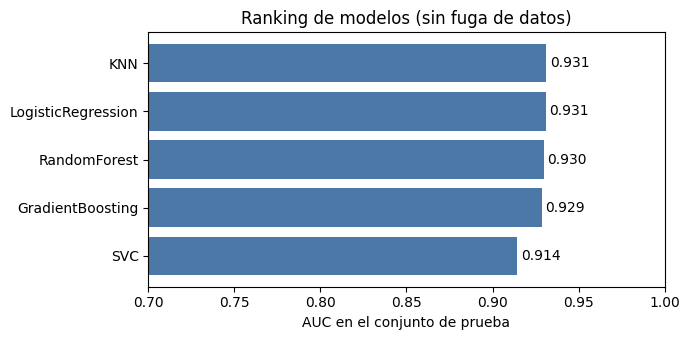

In [9]:
orden = ranking.sort_values("AUC_test")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(orden["modelo"], orden["AUC_test"], color="#4c78a8")
for i, v in enumerate(orden["AUC_test"]):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center")
ax.set_xlim(0.7, 1.0)
ax.set_xlabel("AUC en el conjunto de prueba")
ax.set_title("Ranking de modelos (sin fuga de datos)")
plt.tight_layout()
plt.show()

## 5. Para cerrar la Etapa 1
* El ranking se ordena por **AUC de validación cruzada**, no por el de prueba: así no
  elegimos el modelo mirando el conjunto de prueba.
* Si dos modelos difieren en pocas milésimas de AUC, **no hay diferencia real**; el conjunto
  de prueba es pequeño.
* Escribe en 3–4 líneas tus conclusiones (qué modelo gana, qué tan grande fue la fuga en A
  y B, por qué importa el Pipeline). Eso es lo que pide la tarea para esta etapa.

**Siguiente:** Etapa 2 — división de datos, `Pipeline` + `GridSearchCV`, matriz de
confusión, curva ROC y exportación del modelo.